In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer

from src.alentar_llm.metrics import (calculate_mmd, show_embeddings,
                                     get_top_ngrams, get_meteor, get_rouge,
                                     calculate_all_sms, calculate_self_bleu,
                                     lexical_diversity, calculate_nnd,
                                     get_plagiarism_candidates,
                                     get_bertscore)

/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [8]:
res_list = []

# Load real data 
df_real = pd.read_csv('Informes-Urgencias/EJEI_nocod_Clasificator_2024_07_ 04. 4.fin.csv')
real_reports = df_real['EJEIDiagnóstico'].values
real_reports = [str(v) for v in real_reports]

# Get sentence embedding model
emb_model = SentenceTransformer('all-MiniLM-L6-v2')
emb_real = emb_model.encode(real_reports)

for model_name in ['deepseek-r1',
                   'openbiollm-llama3-70b.i1-q4_k_m.gguf',
                   'qwen3.5:35b-a3b-q8_0']:
    
    # Load synthetic model data
    df_da = pd.read_csv(f'llm_responses_{model_name}.csv', delimiter='|')
    df_da = df_da[df_da['response']!='ERROR']
    da_reports = df_da['response'].values
    da_reports = [str(v) for v in da_reports]
    emb_da = emb_model.encode(da_reports)
    
    row = {}
    row['Model_Name'] = model_name

    # Evaluate synthetic Data Augmentation
    row['MMD ▼'] = calculate_mmd(emb_real, emb_da)
    for key, value in get_rouge(real_reports, da_reports).items():
        row[key + ' ▼'] = value
    row['METEOR ▼'] = get_meteor(real_reports, da_reports)['meteor']
    row['Average_SMS ▼'] = np.mean(calculate_all_sms(real_reports, da_reports))
    row['Self_BLEU ▼'] = calculate_self_bleu(da_reports)
    row['TTR ▲'] = lexical_diversity(da_reports)
    avg_nnd, all_nnds = calculate_nnd(emb_real, emb_da)
    row['Average_NND ▼'] = avg_nnd
    P, R, F1 = get_bertscore(real_reports, da_reports)
    row['Average_BERTScore_F1 ▲'] = F1.mean().item()
    
    res_list.append(row)

/tmp/ipykernel_2486155/2232474246.py:4: DtypeWarning: Columns (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93) have mixed types. Specify dtype option on import or set low_memory=False.
  df_real = pd.read_csv('Informes-Urgencias/EJEI_nocod_Clasificator_2024_07_ 04. 4.fin.csv')
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6241.52it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date

In [16]:
df_results = pd.DataFrame(res_list)
df_results.set_index('Model_Name', inplace=True)
df_style = (df_results.style
            .highlight_min(
                subset=['MMD ▼', 'rouge1 ▼', 'rouge2 ▼', 'rougeL ▼',
                        'rougeLsum ▼', 'METEOR ▼', 'Average_SMS ▼',
                        'Self_BLEU ▼', 'Average_NND ▼'],
                props='font-weight: bold;')
            .highlight_max(
                subset=['TTR ▲', 'Average_BERTScore_F1 ▲'],
                props='font-weight: bold;')
           )
df_style

,MMD ▼,rouge1 ▼,rouge2 ▼,rougeL ▼,rougeLsum ▼,METEOR ▼,Average_SMS ▼,Self_BLEU ▼,TTR ▲,Average_NND ▼,Average_BERTScore_F1 ▲
Model_Name,,,,,,,,,,,
deepseek-r1,0.019661,0.062171,0.005141,0.059342,0.059444,0.043913,0.447607,0.138400,0.985915,0.162660,0.690771
openbiollm-llama3-70b.i1-q4_k_m.gguf,0.028036,0.059589,0.004860,0.055434,0.055711,0.039504,0.392343,0.233253,0.978298,0.180247,0.683144
qwen3.5:35b-a3b-q8_0,0.022550,0.059319,0.002980,0.055824,0.055838,0.045611,0.458146,0.105226,0.991484,0.204041,0.688818


# Show embeddings

In [4]:
emb_model = SentenceTransformer('all-MiniLM-L6-v2')
df_real = pd.read_csv('Informes-Urgencias/EJEI_nocod_Clasificator_2024_07_ 04. 4.fin.csv')
real_reports = df_real['EJEIDiagnóstico'].values
real_reports = [str(v) for v in real_reports]
emb_real = emb_model.encode(real_reports)
emb_da_dict = {}
for model_name in ['deepseek-r1',
                   'openbiollm-llama3-70b.i1-q4_k_m.gguf',
                   'qwen3.5:35b-a3b-q8_0']:
    
    # Load synthetic model data
    df_da = pd.read_csv(f'llm_responses_{model_name}.csv', delimiter='|')
    df_da = df_da[df_da['response']!='ERROR']
    da_reports = df_da['response'].values
    da_reports = [str(v) for v in da_reports]
    emb_da_dict[model_name] = emb_model.encode(da_reports)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6234.59it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_2531795/1457327696.py:2: DtypeWarning: Columns (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93) have mixed types. Specify dtype option on import or set low_memory=False.
  df_real = pd.read_csv('Informes-Urgencias/EJEI_nocod_Clasificator_2024_07_ 04. 4.fin.csv')


/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to to

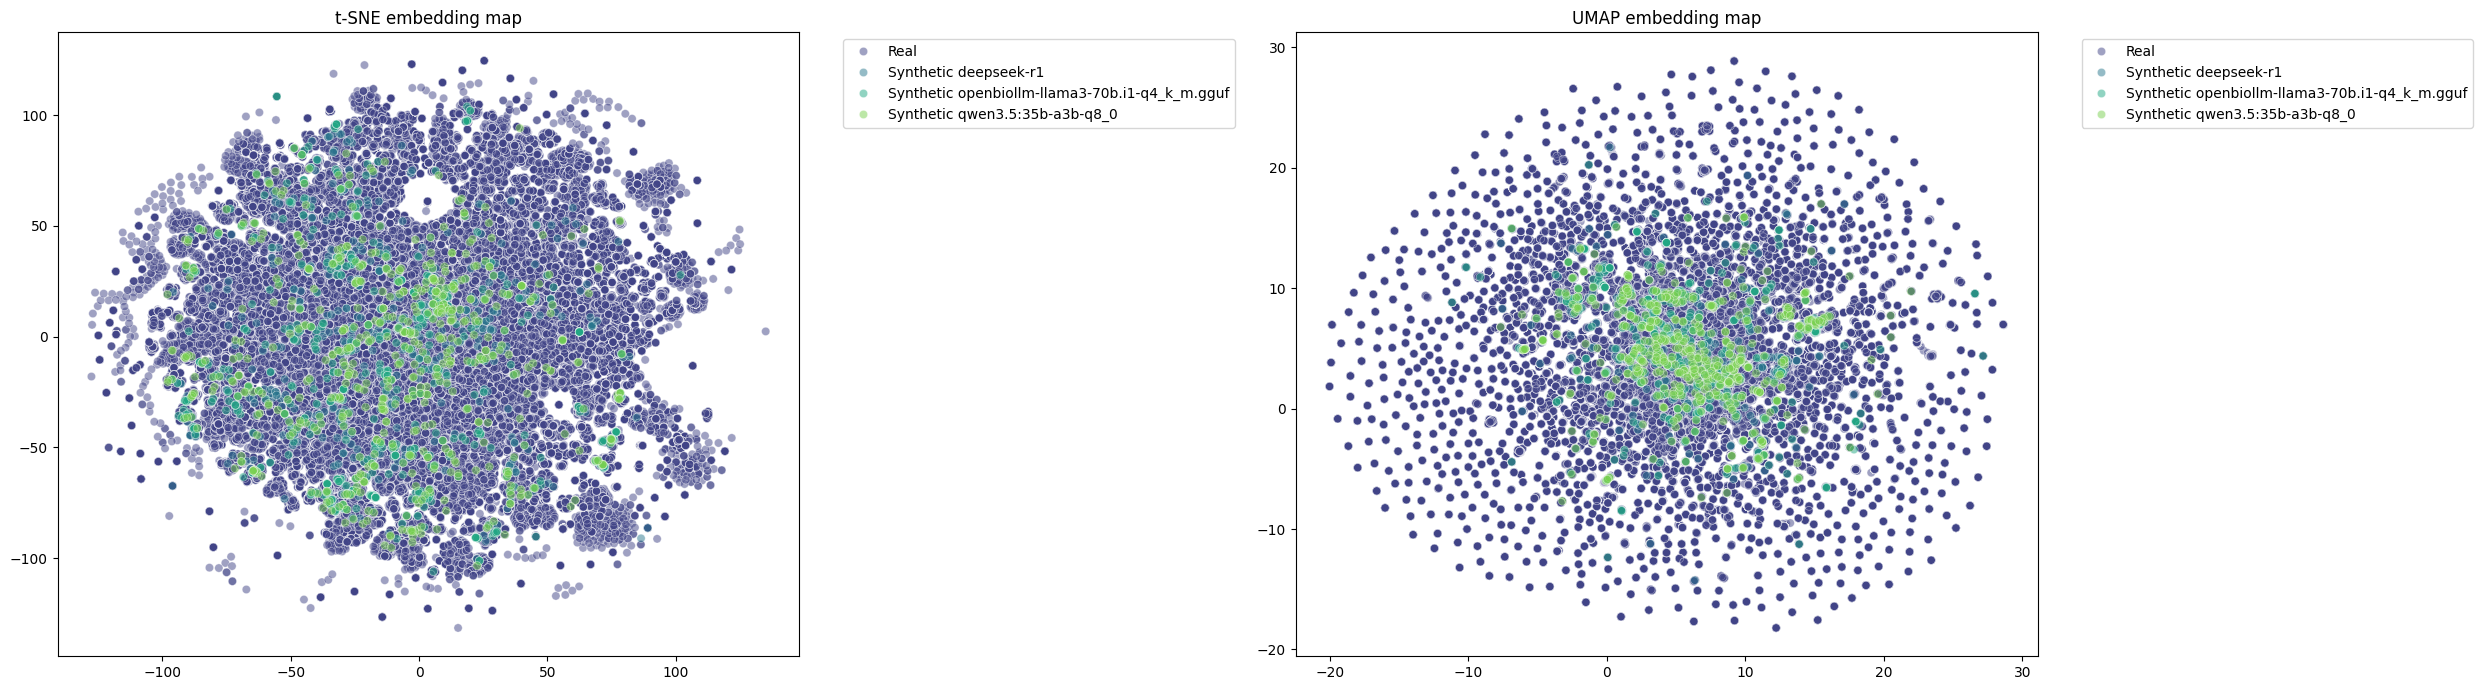

In [6]:
show_embeddings(emb_real, emb_da_dict)

# Top similar n-grams

In [ ]:
n = 2
top_real = get_top_ngrams(real_reports, n=n)
top_da = get_top_ngrams(da_reports, n=n)

print(f"Top Real {n}-grams:", top_real)
print(f"\nTop Synthetic {n}-grams:", top_da)

# Plagiarism detected

In [ ]:
plagiarism_threshold = 0.05 
leaked = np.sum(all_nnds < plagiarism_threshold)
print(f"Reports with suspicion of plagiarism (<{plagiarism_threshold} dist): {leaked}")

df_suspicius = get_plagiarism_candidates(
    da_reports, 
    real_reports, 
    emb_da, 
    emb_real, 
    threshold=plagiarism_threshold
)

df_suspicius